# Recognizing a sketch while it is being drawn

Data: sketches from Google's *Quick, Draw!*. Each sketch is not an image but the **sequence of pen points**, in the order they were drawn.

Model: a **GRU** reads the points one at a time and, after every point, says which object is being drawn (10 classes).

Steps: data → model → hyperparameter choice → training → baseline (logistic regression) → results on the test set (accuracy, confusion matrix, ROC, accuracy vs % of the sketch seen, animation).

In [1]:
import os
import json
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score

from animation import draw, animate

torch.manual_seed(0);

## 1. Data

In [ ]:
CLASSES = ["cat", "bicycle", "pizza", "guitar", "house", "airplane", "fish", "umbrella", "clock", "tree"]
MAX_POINTS = 100     # keep only sketches with at most 100 points (about 90% of them)
N_TRAIN = 10_000     # training sketches per class (70,000 are available, fewer are enough)

# file format (stroke-3): each row of a sketch is (dx, dy, pen_lifted)
#   dx, dy     -> displacement from the previous point
#   pen_lifted -> 1 if the pen leaves the paper after this point (end of a stroke)
# each file already comes split into train / valid / test
def load(split, n=None):
    sketches, labels = [], []
    for i, name in enumerate(CLASSES):
        path = f"data/{name}.npz"
        if not os.path.exists(path):
            urllib.request.urlretrieve(f"https://storage.googleapis.com/quickdraw_dataset/sketchrnn/{name}.npz", path)
        data = np.load(path, allow_pickle=True, encoding="latin1")[split]
        data = [s for s in data if len(s) <= MAX_POINTS][:n]
        sketches += data
        labels += [i] * len(data)

    # sketches have different lengths: put them in one array, filling with zeros (padding)
    X = np.zeros((len(sketches), MAX_POINTS, 3), dtype=np.float32)
    for k, s in enumerate(sketches):
        X[k, :len(s)] = s
    lengths = np.array([len(s) for s in sketches]) # keep trak of the original lenght 
    return X, lengths, np.array(labels)

os.makedirs("data", exist_ok=True) 
X_train, L_train, y_train = load("train", N_TRAIN)  # L_... are the real lenghts 
X_val, L_val, y_val = load("valid")      # to choose hyperparameters 
X_test, L_test, y_test = load("test")    # used only once, for the final results

# dx and dy are in pixels (values up to hundreds): bring them to a scale of ~1
# using the standard deviation of the training set only
scale = X_train[..., :2][X_train[..., :2] != 0].std()
for X in (X_train, X_val, X_test):
    X[..., :2] /= scale

print("train:", X_train.shape, "  validation:", X_val.shape, "  test:", X_test.shape)

train: (100000, 100, 3)   validation: (23609, 100, 3)   test: (23537, 100, 3)


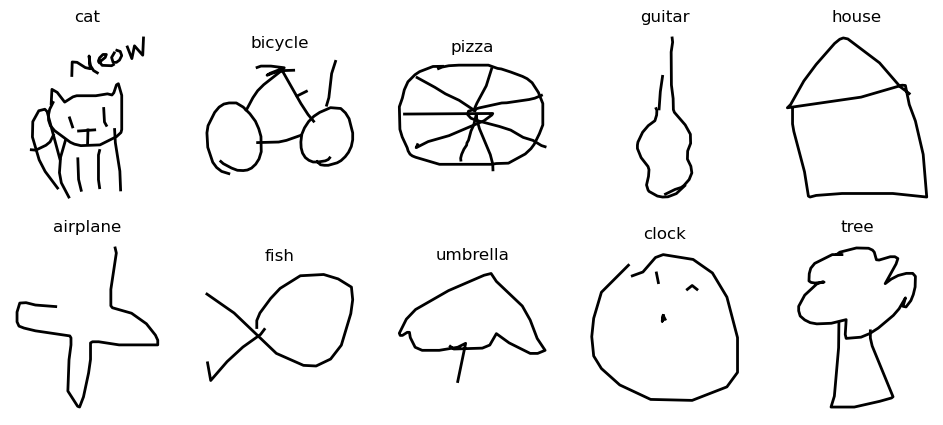

In [3]:
# one example per class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    k = np.where(y_train == i)[0][0]
    draw(ax, X_train[k, :L_train[k]])
    ax.set_title(CLASSES[i])
plt.show()

## 2. Model: GRU

In [4]:
class GRUClassifier(nn.Module):
    def __init__(self, hidden, n_classes=10):
        super().__init__()
        # 2 GRU layers: read the points one at a time, updating the memory (hidden state)
        self.gru = nn.GRU(input_size=3, hidden_size=hidden, num_layers=2, batch_first=True)
        # from the memory to the 10 classes
        self.out = nn.Linear(hidden, n_classes)

    def forward(self, x):
        h, _ = self.gru(x)     # h = memory after every point: (sketches, points, hidden)
        return self.out(h)     # so there is a prediction after EVERY point: (sketches, points, classes)

In [5]:
loss_fn = nn.CrossEntropyLoss()
BATCH = 256

def masked_loss(logits, lengths, labels):
    # the loss is computed after EVERY point of the sketch, not only at the end:
    # this way the network learns to recognize unfinished sketches too.
    # the mask keeps only the real points (drops the padding after the end of the sketch)
    mask = torch.arange(logits.shape[1])[None, :] < lengths[:, None]
    target = labels[:, None].expand(-1, logits.shape[1])
    return loss_fn(logits[mask], target[mask])

@torch.no_grad()
def evaluate(model, X, L, y):
    # loss, final accuracy and probabilities after every point (in blocks to keep memory low)
    model.eval()
    loss, probs = 0.0, []
    for i in range(0, len(X), 2000):
        logits = model(torch.tensor(X[i:i + 2000]))
        loss += masked_loss(logits, torch.tensor(L[i:i + 2000]), torch.tensor(y[i:i + 2000])).item() * len(logits)
        probs.append(torch.softmax(logits, dim=-1).numpy())
    probs = np.concatenate(probs)
    accuracy = (probs[np.arange(len(X)), L - 1].argmax(axis=1) == y).mean()   # answer after the last real point
    return loss / len(X), accuracy, probs

def train(model, X, L, y, epochs, lr):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    X, L, y = torch.tensor(X), torch.tensor(L), torch.tensor(y)
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), BATCH):
            idx = order[i:i + BATCH]
            loss = masked_loss(model(X[idx]), L[idx], y[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)
        val_loss, val_acc, _ = evaluate(model, X_val, L_val, y_val)
        history["train_loss"].append(total / len(X))
        history["val_loss"].append(val_loss)
        print(f"  epoch {epoch + 1}/{epochs}   train loss {total / len(X):.3f}   val loss {val_loss:.3f}   val acc {val_acc:.1%}")
    return history

## 3. Choosing the hyperparameters

In [6]:
# small grid: memory size x learning rate.
# each combination: 2 epochs on a random subset of 30,000 training sketches, scored on the validation set
SEARCH_FILE = "hparam_search.json"
if os.path.exists(SEARCH_FILE):
    search = json.load(open(SEARCH_FILE))
else:
    subset = np.random.default_rng(0).choice(len(X_train), 30_000, replace=False)
    search = []
    for hidden in [64, 128]:
        for lr in [1e-3, 3e-3]:
            print(f"hidden={hidden}, lr={lr}")
            torch.manual_seed(0)
            model = GRUClassifier(hidden)
            train(model, X_train[subset], L_train[subset], y_train[subset], epochs=2, lr=lr)
            search.append({"hidden": hidden, "lr": lr, "val_acc": float(evaluate(model, X_val, L_val, y_val)[1])})
    json.dump(search, open(SEARCH_FILE, "w"), indent=1)

for s in search:
    print(f"hidden={s['hidden']:4d}   lr={s['lr']:.0e}   validation accuracy {s['val_acc']:.1%}")
best = max(search, key=lambda s: s["val_acc"])
print("chosen:", best)

hidden=  64   lr=1e-03   validation accuracy 48.3%
hidden=  64   lr=3e-03   validation accuracy 67.8%
hidden= 128   lr=1e-03   validation accuracy 54.8%
hidden= 128   lr=3e-03   validation accuracy 78.0%
chosen: {'hidden': 128, 'lr': 0.003, 'val_acc': 0.7799144394087001}


## 4. Training

loaded trained model from gru_model.pt


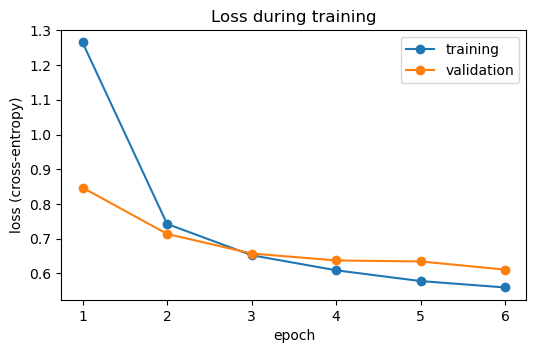

In [7]:
# final training with the chosen hyperparameters on the full training set.
# weights and loss history are saved: if the file exists they are loaded instead of training again
EPOCHS = 6           # ~1.5 minutes per epoch on CPU (MacBook M1)
MODEL_FILE = "gru_model.pt"

torch.manual_seed(0)
model = GRUClassifier(best["hidden"])
if os.path.exists(MODEL_FILE):
    saved = torch.load(MODEL_FILE)
    model.load_state_dict(saved["weights"])
    history = saved["history"]
    print("loaded trained model from", MODEL_FILE)
else:
    history = train(model, X_train, L_train, y_train, EPOCHS, best["lr"])
    torch.save({"weights": model.state_dict(), "history": history}, MODEL_FILE)

epochs = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(6, 3.5))
plt.plot(epochs, history["train_loss"], "o-", label="training")
plt.plot(epochs, history["val_loss"], "o-", label="validation")
plt.xlabel("epoch")
plt.ylabel("loss (cross-entropy)")
plt.legend()
plt.title("Loss during training")
plt.show()

## 5. Baseline: logistic regression

In [8]:
# softmax (multinomial logistic) regression on the whole sketch flattened into 100*3 numbers:
# one linear layer + softmax trained with cross-entropy, like the GRU but with no memory
# and no notion of order (each number has a fixed weight tied to its position)
baseline = LogisticRegression(max_iter=300)
baseline.fit(X_train.reshape(len(X_train), -1), y_train)

LogisticRegression(max_iter=300)

## 6. Results on the test set

In [9]:
test_loss, test_acc, probs = evaluate(model, X_test, L_test, y_test)
final_probs = probs[np.arange(len(X_test)), L_test - 1]     # probabilities after the last real point
final_pred = final_probs.argmax(axis=1)

baseline_acc = (baseline.predict(X_test.reshape(len(X_test), -1)) == y_test).mean()

print(f"test accuracy   GRU: {test_acc:.1%}   logistic regression: {baseline_acc:.1%}   random guessing: {1 / len(CLASSES):.0%}\n")
print(classification_report(y_test, final_pred, target_names=CLASSES, digits=3))

test accuracy   GRU: 95.5%   logistic regression: 54.0%   random guessing: 10%

              precision    recall  f1-score   support

         cat      0.870     0.974     0.919      2232
     bicycle      0.954     0.984     0.969      2314
       pizza      0.873     0.977     0.922      2026
      guitar      0.978     0.974     0.976      2274
       house      0.985     0.978     0.982      2500
    airplane      0.967     0.917     0.941      2500
        fish      0.973     0.939     0.956      2500
    umbrella      0.982     0.960     0.971      2500
       clock      0.997     0.900     0.946      2500
        tree      0.979     0.963     0.971      2191

    accuracy                          0.955     23537
   macro avg      0.956     0.957     0.955     23537
weighted avg      0.958     0.955     0.956     23537



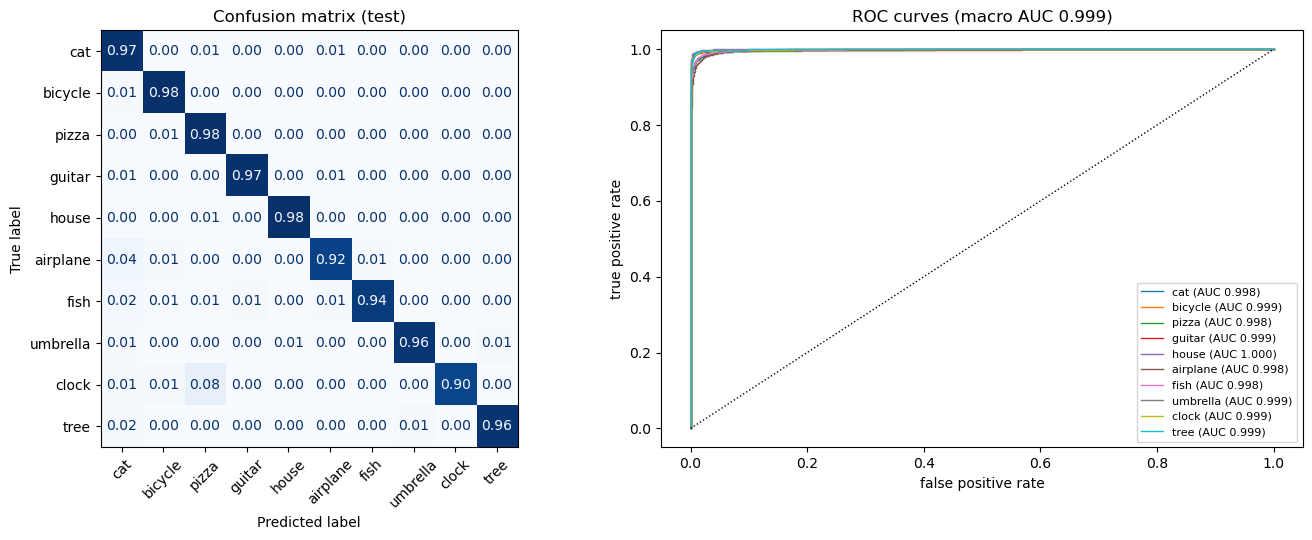

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# confusion matrix, normalized per row: each row = true class, values = fraction of its sketches
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=CLASSES, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=axes[0])
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Confusion matrix (test)")

# ROC curves, one class against all the others
for i, name in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test == i, final_probs[:, i])
    axes[1].plot(fpr, tpr, lw=1, label=f"{name} (AUC {roc_auc_score(y_test == i, final_probs[:, i]):.3f})")
axes[1].plot([0, 1], [0, 1], "k:", lw=1)
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
axes[1].set_title(f"ROC curves (macro AUC {roc_auc_score(y_test, final_probs, multi_class='ovr'):.3f})")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### How much of the sketch is needed to recognize it?

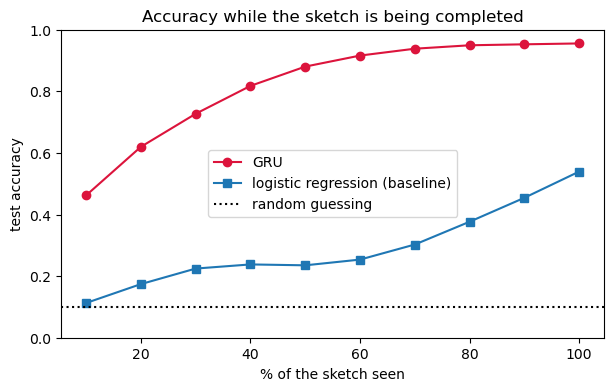

 10% of the sketch -> GRU 46.2%   logistic regression 11.3%
 20% of the sketch -> GRU 62.0%   logistic regression 17.4%
 30% of the sketch -> GRU 72.7%   logistic regression 22.5%
 40% of the sketch -> GRU 81.8%   logistic regression 23.8%
 50% of the sketch -> GRU 88.0%   logistic regression 23.5%
 60% of the sketch -> GRU 91.6%   logistic regression 25.4%
 70% of the sketch -> GRU 93.8%   logistic regression 30.3%
 80% of the sketch -> GRU 94.9%   logistic regression 37.7%
 90% of the sketch -> GRU 95.3%   logistic regression 45.4%
100% of the sketch -> GRU 95.5%   logistic regression 54.0%


In [11]:
# for each percentage, look at the answer after that fraction of the points
percentages = np.arange(10, 101, 10)
gru_partial, baseline_partial = [], []
for p in percentages:
    k = np.maximum(1, np.round(p / 100 * L_test).astype(int)) - 1     # index of the point at p% of each sketch
    gru_partial.append((probs[np.arange(len(X_test)), k].argmax(axis=1) == y_test).mean())

    # the baseline sees the same first p% of each sketch, the rest set to zero (as in the padding)
    seen = np.arange(MAX_POINTS)[None, :] <= k[:, None]
    X_seen = (X_test * seen[..., None]).reshape(len(X_test), -1)
    baseline_partial.append((baseline.predict(X_seen) == y_test).mean())

plt.figure(figsize=(7, 4))
plt.plot(percentages, gru_partial, "o-", color="crimson", label="GRU")
plt.plot(percentages, baseline_partial, "s-", color="tab:blue", label="logistic regression (baseline)")
plt.axhline(1 / len(CLASSES), color="black", ls=":", label="random guessing")
plt.xlabel("% of the sketch seen")
plt.ylabel("test accuracy")
plt.ylim(0, 1)
plt.legend()
plt.title("Accuracy while the sketch is being completed")
plt.show()

for p, g, b in zip(percentages, gru_partial, baseline_partial):
    print(f"{p:3d}% of the sketch -> GRU {g:.1%}   logistic regression {b:.1%}")

### Animation

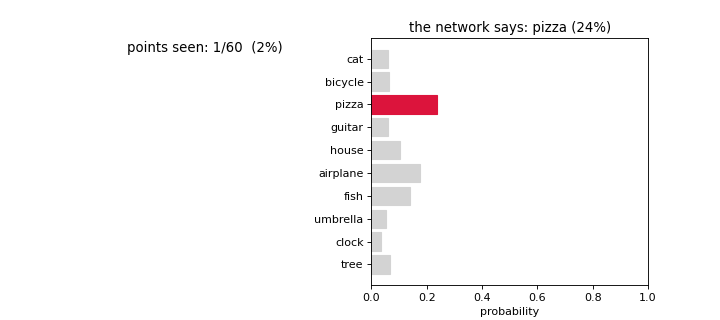

In [12]:
# a test cat that the network has not recognized yet at half sketch,
# but recognizes with more than 95% confidence at the end
half = probs[np.arange(len(X_test)), L_test // 2 - 1].argmax(axis=1)
k = np.where((y_test == 0) & (final_probs[:, 0] > 0.95) & (half != 0))[0][0]

animate(X_test[k, :L_test[k]], probs[k, :L_test[k]], CLASSES, "cat.gif")
Image(filename="cat.gif")